In [290]:
%matplotlib inline

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from ipywidgets import VBox, HBox, FloatSlider, Output, Label, Dropdown, FloatLogSlider, HTML, Checkbox
from scipy.interpolate import RegularGridInterpolator
from IPython.display import display, clear_output, Audio
import sys
import PathGeneration as pg
from Interpolation import SplineTrajectory3D
import json
import cv2
from moviepy import VideoFileClip
import matplotlib as mpl
from scipy.special import jv
from matplotlib.patches import Circle

In [291]:
todeg = 180 / np.pi
def computeZ(mp, k):
    return np.array([np.exp(np.dot(k, mp[i])*1j) for i in range(len(mp))])

def plot_mesh_polar(ax, plot_points, z):
    aziv, zeniv = plot_points
    c = ax.pcolormesh(aziv, zeniv * todeg, np.abs(z), shading='gouraud', cmap='viridis')
    ax.set_ylim([0, 90 + 1e-5])
    plt.colorbar(c, ax=ax)

def polar_to_look_direction(aziv, zeniv):
    return np.stack((
        np.cos(aziv) * np.sin(zeniv),
        np.sin(aziv) * np.sin(zeniv),
        np.cos(zeniv)), axis=-1)

def create_look_directions(n, fov):

    fov += 1e-5
    x = np.linspace(-fov, fov, n)
    y = np.linspace(-fov, fov, n)

    xv, yv = np.meshgrid(x, y)

    # circle the square
    # ratio = np.maximum(np.abs(xv), np.abs(yv)) / (np.sqrt(xv*xv + yv*yv) + 1e-18)
    # xv *= ratio
    # yv *= ratio
    
    xv = np.reshape(xv, -1)
    yv = np.reshape(yv, -1)
    aziv = np.atan2(yv, xv)
    zeniv = np.sqrt(xv*xv + yv*yv)

    unit_look_direction = polar_to_look_direction(aziv, zeniv)
    
    # xy = np.stack((xv, yv), axis = -1)

    return (unit_look_direction, aziv, zeniv, (x, y))

def create_distance_vectors(look_directions, microphone_positions):
    return look_directions @ microphone_positions

def create_steering_vectors(distance_vectors, k):
    return np.exp(1j * distance_vectors * k)

class ArrayState:
    positions = np.array([[0, 0, 0]])
    cropac = {}
    calibration = np.array([])
    def __init__(self, pos=np.array([[0, 0, 0]]), cropac={}):
        self.positions = pos
        self.cropac = cropac

def load_array(path, calibrationPath):

    array = ArrayState()
    with open(path, "r", encoding="utf-8") as f:
        array.__dict__ = json.load(f)
    array.positions = np.stack((*np.array(array.positions).T, np.zeros(len(array.positions))))
    
    with open(calibrationPath, "r", encoding="utf-8") as f:
        array.calibration = np.array(json.load(f))

    array.positions[0] -= np.mean(array.positions[0])
    array.positions[1] -= np.mean(array.positions[1])
    
    return array

def default8():
    return load_array("default_array8_1.json", "default_array8_calibration_old.json")

def circle8():
    return load_array("circle_array8.json", "circle_array8_calibration.json")

In [292]:
# CroPaC for a planar circular array

def planar_directions(directions):
    return np.atan2(directions[:,1], directions[:,0])

def zeni_directions(directions):
    return np.atan2(np.sqrt(directions[:,0]**2 + directions[:,1]**2), directions[:,2])

def polar_to_unitdir(aziv, zeniv):
    unit_look_direction = np.stack((
        np.cos(aziv) * np.sin(zeniv),
        np.sin(aziv) * np.sin(zeniv),
        np.cos(zeniv)), axis=-1)
    return unit_look_direction

def create_cropac_weights(look_direction, look_vector, mic_array, k):

    mic = planar_directions(mic_array.T)
    dir = planar_directions(look_direction[None,:])
    relative_angles = dir[0] - mic

    m = mic_array.shape[1]
    r = np.sqrt(np.sum(mic_array[:,0] * mic_array[:,0]))

    o1 = 1
    o2 = 2

    dj_zeros = [0, 1.8411837813, 3.0542369282, 4.2011889412]

    w1_zeni = np.arcsin(min(1, dj_zeros[o1] / (k * r)))
    w2_zeni = np.arcsin(min(1, dj_zeros[o2] / (k * r)))
    look_zeni = zeni_directions(look_direction[None,:])[0]

    zeni_steer = min(1, k * r / dj_zeros[o1])**2
    zeni_steer1 = k * r * (np.sin(w1_zeni) - np.sin(look_zeni)) * zeni_steer
    zeni_steer2 = k * r * (np.sin(w2_zeni) - np.sin(look_zeni)) * zeni_steer

    kr1z = dj_zeros[o1] - zeni_steer1
    kr2z = dj_zeros[o2] - zeni_steer2
    zeni_steer2 += (kr2z - kr1z) * zeni_steer

    kr1n = min(k * r + zeni_steer1, dj_zeros[o1])
    kr2n = min(k * r + zeni_steer2, dj_zeros[o2])

    w1 = np.cos(o1 * relative_angles) * (1j**o1) / (jv(o1, kr1n)) / m
    w2 = np.cos(o2 * relative_angles) * (1j**o2) / (jv(o2, kr2n)) / m

    dv0 = create_distance_vectors(polar_to_unitdir(dir, np.array([np.pi/2])), mic_array)

    sv1 = create_steering_vectors(dv0, zeni_steer1 / r)
    sv2 = create_steering_vectors(dv0, zeni_steer2 / r)

    correction1 = np.conj(sv1)
    correction2 = np.conj(sv2)

    w1 = w1 * correction1[0]
    w2 = w2 * correction2[0]

    das_w1 = look_vector / m * 2
    das_w2 = look_vector / m * 2

    for i in range(8):
        if i&1:
            das_w2[i] = 0
        else:
            das_w1[i] = 0

    j0_zero = 2.4048
    mlw = np.arcsin(min(1, j0_zero / (k*r)))

    bstart = 45 / todeg
    bend = 30 / todeg
    mlw = min(bstart, max(mlw, bend))

    blend = (mlw - bend) / (bstart - bend)

    w1 = w1 * blend + das_w1 * (1 - blend)
    w2 = w2 * blend + das_w2 * (1 - blend)

    return w1, w2

def create_cropac_weights2(look_direction, look_vector, mic_array, k):

    mic = planar_directions(mic_array.T)
    dir = planar_directions(look_direction[None,:])
    relative_angles = dir[0] - mic

    m = mic_array.shape[1]
    r = np.sqrt(np.sum(mic_array[:,0] * mic_array[:,0]))

    o1 = 1
    o2 = 2

    dj_zeros = [0, 1.8411837813, 3.0542369282, 4.2011889412]

    w1_zeni = np.arcsin(min(1, dj_zeros[o1] / (k * r)))
    w2_zeni = np.arcsin(min(1, dj_zeros[o2] / (k * r)))
    look_zeni = zeni_directions(look_direction[None,:])[0]

    zeni_steer = 1 # min(1, k * r / dj_zeros[o1])**2
    zeni_steer1 = dj_zeros[o1] # k * r * (np.sin(w1_zeni) - np.sin(look_zeni)) * zeni_steer
    zeni_steer2 = k * r * (np.sin(w2_zeni) - np.sin(look_zeni)) * zeni_steer

    kr1z = dj_zeros[o1] - zeni_steer1
    kr2z = dj_zeros[o2] - zeni_steer2
    zeni_steer2 += (kr2z - kr1z) * zeni_steer

    kr1n = min(k * r + zeni_steer1, dj_zeros[o1])
    kr2n = min(k * r + zeni_steer2, dj_zeros[o2])

    w1 = np.cos(o1 * relative_angles) * (1j**o1) / (jv(o1, kr1n)) / m
    w2 = np.cos(o2 * relative_angles) * (1j**o2) / (jv(o2, kr2n)) / m

    dv0 = create_distance_vectors(polar_to_unitdir(dir, np.array([np.pi/2])), mic_array)

    sv1 = create_steering_vectors(dv0, zeni_steer1 / r)
    sv2 = create_steering_vectors(dv0, zeni_steer2 / r)

    correction1 = np.conj(sv1)
    correction2 = np.conj(sv2)

    w1 = w1 * correction1[0]
    w2 = w2 * correction2[0]

    das_w1 = look_vector / m * 2
    das_w2 = look_vector / m * 2

    for i in range(8):
        if i&1:
            das_w2[i] = 0
        else:
            das_w1[i] = 0

    j0_zero = 2.4048
    mlw = np.arcsin(min(1, j0_zero / (k*r)))

    bstart = 45 / todeg
    bend = 30 / todeg
    mlw = min(bstart, max(mlw, bend))

    blend = 1 # (mlw - bend) / (bstart - bend)

    w1 = w1 * blend + das_w1 * (1 - blend)
    w2 = w2 * blend + das_w2 * (1 - blend)

    return w1, w2

def cropac_beamform(look_directions, steering_vectors, mic_array, k, x):
    
    m = steering_vectors.shape[1]
    w1 = np.zeros_like(steering_vectors)
    w2 = np.zeros_like(steering_vectors)

    for i in range(steering_vectors.shape[0]):
        ww1, ww2 = create_cropac_weights(look_directions[i], steering_vectors[i], mic_array, k)
        w1[i,:] = ww1
        w2[i,:] = ww2

    # x /= np.abs(x)
    # print(np.abs(x))

    z1 = np.conj(w1) @ x
    z2 = np.conj(w2) @ x
    das = np.conj(steering_vectors) @ x / m

    norm = np.sum(np.abs(x)**2) / m

    return das * np.maximum(0, np.real(np.conj(z1) * z2) / norm)

def cropac_beampattern(look_direction, look_vector, steering_vectors, mic_array, k):

    w1, w2 = create_cropac_weights(look_direction, look_vector, mic_array, k)

    m = steering_vectors.shape[1]
    z1 = steering_vectors @ np.conj(w1)
    z2 = steering_vectors @ np.conj(w2)
    das = steering_vectors @ np.conj(look_vector) / m

    return das * np.maximum(0, np.real(np.conj(z1) * z2))

In [293]:
def plot_mesh_polar(ax, plot_points, z):
    aziv, zeniv = plot_points
    c = ax.pcolormesh(aziv, zeniv * todeg, np.abs(z), shading='gouraud', cmap='viridis')
    ax.set_ylim([0, 90 + 1e-5])
    plt.colorbar(c, ax=ax)

def plot_mesh_planar(ax, plot_points, z):
    xv, yv = plot_points
    c = ax.pcolormesh(xv, yv, np.abs(z), shading='gouraud', cmap='viridis')
    plt.colorbar(c, ax=ax)

<>:140: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:147: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:140: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:147: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/l0/9fzt8fvj0zqdh211mn6mc0000000gp/T/ipykernel_74262/4230120086.py:140: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  ax2.set_title("$(\mathbf{v}(K_p)^*/N) \odot \mathbf{w}$")
/var/folders/l0/9fzt8fvj0zqdh211mn6mc0000000gp/T/ipykernel_74262/4230120086.py:147: Synta

<Figure size 640x480 with 0 Axes>

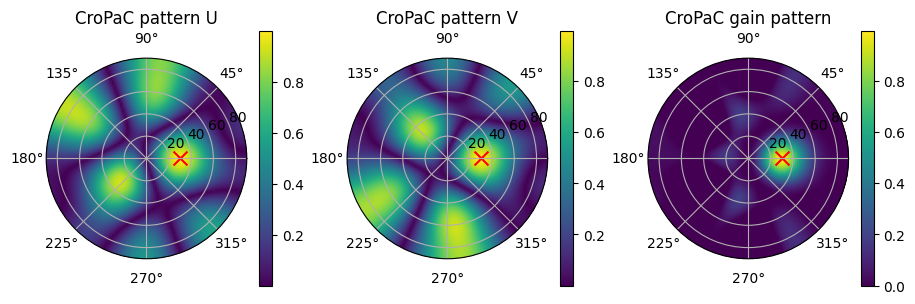

In [313]:
k = 45
beamforming_resolution = 100
fov = 90 / todeg
fig_width = 11
t = 1

look_directions, aziv, zeniv, xy = create_look_directions(beamforming_resolution, fov)
plot_points = (aziv.reshape((beamforming_resolution, beamforming_resolution)),
               zeniv.reshape((beamforming_resolution, beamforming_resolution)))

dk = 120
kx = np.linspace(-dk, dk, beamforming_resolution * 2)
ky = np.linspace(-dk, dk, beamforming_resolution * 2)
vkx, vky = np.meshgrid(kx, ky)
fvkx = vkx.flatten()
fvky = vky.flatten()
kk = np.vstack((fvkx, fvky, np.zeros_like(fvkx)))

mp = circle8().positions
m = mp.shape[1]
adir, zdir = 0, 30
ld_udir = polar_to_look_direction(adir / todeg, zdir / todeg)
ld_steer = create_steering_vectors(create_distance_vectors(np.array([ld_udir]), mp), k)[0]

dv = create_distance_vectors(look_directions, mp)
steering_vectors = create_steering_vectors(dv, k)
ksteering = computeZ(mp.T, kk.T).T

if True:
    plt.figure()
    w1, w2 = create_cropac_weights(ld_udir, ld_steer, mp, k)

    z1 = steering_vectors @ np.conj(w1)
    z2 = steering_vectors @ np.conj(w2)

    g = np.maximum(0, np.real(np.conj(z1) * z2))

    fig = plt.figure(figsize=(fig_width, fig_width * 0.3))
    ax1 = fig.add_subplot(1, 3, 1, projection='polar')
    ax2 = fig.add_subplot(1, 3, 2, projection='polar')
    ax3 = fig.add_subplot(1, 3, 3, projection='polar')

    plot_mesh_polar(ax1, plot_points, z1.reshape(plot_points[0].shape))
    plot_mesh_polar(ax2, plot_points, z2.reshape(plot_points[0].shape))
    plot_mesh_polar(ax3, plot_points, g.reshape(plot_points[0].shape))

    ax1.scatter(adir / todeg, zdir, marker='x', color='red', s=100)
    ax2.scatter(adir / todeg, zdir, marker='x', color='red', s=100)
    ax3.scatter(adir / todeg, zdir, marker='x', color='red', s=100)

    ax3.set_title('CroPaC gain pattern')
    ax1.set_title('CroPaC pattern U')
    ax2.set_title('CroPaC pattern V')
    plt.show()

if False:
    plt.figure()
    w = ld_steer / m
    z1 = steering_vectors @ np.conj(w)
    z2 = ksteering @ np.conj(w)

    fig = plt.figure(figsize=(fig_width, fig_width * 0.365))
    ax1 = fig.add_subplot(1, 2, 1, projection='polar')
    ax2 = fig.add_subplot(1, 2, 2)

    plot_mesh_polar(ax1, plot_points, z1.reshape(plot_points[0].shape))
    plot_mesh_planar(ax2, (vkx, vky), z2.reshape(vkx.shape))

    # Center (x0, y0) and radius r in data units
    circle = Circle((0, 0), k, edgecolor='red', facecolor='none', linewidth=1)  # facecolor='none' gives outline only
    ax2.add_patch(circle)

    ax2.axis('equal')
    plt.show()

if False:
    plt.figure()
    w = ld_steer / m
    z1 = steering_vectors @ np.conj(w)
    z2 = ksteering @ np.conj(w)

    fig = plt.figure(figsize=(fig_width, fig_width * 0.33))
    ax2 = fig.add_subplot(1, 1, 1)

    plot_mesh_planar(ax2, (vkx, vky), z2.reshape(vkx.shape))

    # Center (x0, y0) and radius r in data units
    circle = Circle((0, 0), k, edgecolor='red', facecolor='none', linewidth=1)  # facecolor='none' gives outline only
    ax2.add_patch(circle)
    ax2.set_xlabel(f"$k_x$")
    ax2.set_ylabel(f"$k_y$")

    plt.show()

if False:
    plt.figure()
    w1, _ = create_cropac_weights2(ld_udir, ld_steer, mp, k)
    w2, _ = create_cropac_weights(ld_udir, ld_steer, mp, k)
    z1 = ksteering @ np.conj(w1)
    z2 = ksteering @ np.conj(w2)

    fig = plt.figure(figsize=(fig_width, fig_width*0.365))
    ax1 = fig.add_subplot(1, 2, 1)
    ax2 = fig.add_subplot(1, 2, 2)

    plot_mesh_planar(ax1, (vkx, vky), z1.reshape(vkx.shape))
    plot_mesh_planar(ax2, (vkx, vky), z2.reshape(vkx.shape))

    x, y, z = polar_to_look_direction(adir / todeg, zdir / todeg)
    ax1.scatter(x * k, y * k, marker='x', color='red', s=100)
    ax2.scatter(x * k, y * k, marker='x', color='red', s=100)

    ax1.annotate(
        f"$K_p$",
        (x * k, y * k),
        textcoords="offset points",
        xytext=(4, 4),
        fontsize=20,
        color='red',
        ha='left',
        va='bottom'
    )
    ax2.annotate(
            f"$K_p$",
            (x * k, y * k),
            textcoords="offset points",
            xytext=(4, 4),
            fontsize=20,
            color='red',
            ha='left',
            va='bottom'
        )

    # Center (x0, y0) and radius r in data units
    circle = Circle((0, 0), k, edgecolor='red', facecolor='none', linewidth=1)  # facecolor='none' gives outline only
    ax2.add_patch(circle)
    ax2.axis('equal')
    ax2.set_xlabel(f"$k_x$")
    ax2.set_ylabel(f"$k_y$")
    ax2.set_title("$(\mathbf{v}(K_p)^*/N) \odot \mathbf{w}$")

    circle = Circle((0, 0), k, edgecolor='red', facecolor='none', linewidth=1)  # facecolor='none' gives outline only
    ax1.add_patch(circle)
    ax1.axis('equal')
    ax1.set_xlabel(f"$k_x$")
    ax1.set_ylabel(f"$k_y$")
    ax1.set_title("$\mathbf{w}$")

    plt.show()

if False:
    plt.figure()
    w1, _ = create_cropac_weights(ld_udir, ld_steer, mp, k)
    w2, _ = create_cropac_weights2(ld_udir, ld_steer, mp, k)
    z1 = ksteering @ np.conj(w1)
    z2 = ksteering @ np.conj(w2)

    fig = plt.figure(figsize=(fig_width, fig_width * 0.365))
    ax1 = fig.add_subplot(1, 2, 1)
    ax2 = fig.add_subplot(1, 2, 2)

    plot_mesh_planar(ax1, (vkx, vky), z1.reshape(vkx.shape))
    plot_mesh_planar(ax2, (vkx, vky), z2.reshape(vkx.shape))

    # Center (x0, y0) and radius r in data units
    circle = Circle((0, 0), k, edgecolor='red', facecolor='none', linewidth=1)  # facecolor='none' gives outline only
    ax2.add_patch(circle)
    ax2.set_xlabel(f"$k_x$")
    ax2.set_ylabel(f"$k_y$")
    ax2.axis('equal')

    circle = Circle((0, 0), k, edgecolor='red', facecolor='none', linewidth=1)  # facecolor='none' gives outline only
    ax1.add_patch(circle)
    ax1.set_xlabel(f"$k_x$")
    ax1.set_ylabel(f"$k_y$")
    ax1.axis('equal')

    plt.show()
